# Transformer. Seminar 4. Hugging Face и BERT

На прошлом семинаре разобрали, откуда берутся номера токенов. До BERT не дошли. Сегодня с нуля: как взять готовую модель и что она делает с предложением.

Блоки энкодера собирали на семинаре 2. Здесь их не пишем. Берём маленький обученный BERT и смотрим вход, векторы и спрятанное слово.

В конце — как это учили в статье 2019 года и чем от того BERT отличаются RoBERTa, XLM-RoBERTa и DeBERTa.


## 0. Зависимости


In [126]:
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path(".mplconfig").resolve()))
os.environ.setdefault("HF_HOME", str(Path(".hf_cache").resolve()))

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.set_num_threads(min(2, os.cpu_count() or 1))
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.family"] = "DejaVu Sans"


def show_tokens(rows, title=None):
    fig, ax = plt.subplots(figsize=(9, 0.46 * len(rows) + 0.55))
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.55, len(rows) - 0.45)
    ax.axis("off")
    for i, (label, toks) in enumerate(rows):
        y = len(rows) - 1 - i
        ax.text(0.0, y, label, ha="left", va="center", fontsize=11, color="#333")
        weights = [max(len(tok), 1) for tok in toks]
        x = 0.24
        usable = 0.74
        gap = 0.008 * (len(toks) > 1)
        scale = (usable - gap * (len(toks) - 1)) / sum(weights)
        for tok, w in zip(toks, weights):
            width = max(scale * w, 0.045)
            color = "#d9d9d9" if tok in ("[UNK]", "[PAD]") else plt.cm.Set2(hash(tok) % 8)
            ax.add_patch(plt.Rectangle((x, y - 0.32), width, 0.64, facecolor=color, edgecolor="#333", lw=0.6))
            ax.text(x + width / 2, y, tok, ha="center", va="center", fontsize=11)
            x += width + gap
    if title:
        ax.set_title(title, loc="left", fontsize=12)
    plt.tight_layout()
    plt.show()


def plot_attention(weights, x_labels, y_labels, title, ax, fontsize=8, colorbar=True):
    weights = weights.detach().cpu()
    im = ax.imshow(weights, cmap="viridis", vmin=0.0, vmax=1.0)
    ax.set_title(title, fontsize=fontsize + 2)
    ax.set_xlabel("ключ", fontsize=fontsize)
    ax.set_ylabel("запрос", fontsize=fontsize)
    ax.set_xticks(range(len(x_labels)))
    ax.set_xticklabels(x_labels, rotation=40, ha="right", fontsize=fontsize)
    ax.set_yticks(range(len(y_labels)))
    ax.set_yticklabels(y_labels, fontsize=fontsize)
    for i in range(weights.size(0)):
        for j in range(weights.size(1)):
            val = weights[i, j].item()
            color = "black" if val > 0.45 else "white"
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=color, fontsize=fontsize)
    if colorbar:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)


print("torch:", torch.__version__)


torch: 2.8.0


## 1. Hugging Face

Две разные вещи с одним именем.

Hub — склад моделей. Адрес папки выглядит как `cointegrated/rubert-tiny2`: организация и короткое имя. Внутри конфиг, словарь и веса.

Библиотека `transformers` эти файлы читает. Вызов один: `from_pretrained`. `AutoTokenizer` и `AutoModel` смотрят поле `model_type` в конфиге и сами выбирают класс. Здесь это `bert`, поэтому поднимется BERT, не GPT.

В аудитории папку не качаем. Она лежит в `models/rubert-tiny2`. Флаг `local_files_only=True` не пускает в сеть. С Hub строка была бы `"cointegrated/rubert-tiny2"`, вызов тот же.


In [127]:
folder = Path("models/rubert-tiny2")
for path in sorted(folder.iterdir()):
    print(f"{path.name:22} {path.stat().st_size / 1e6:6.2f} МБ")


README.md                0.00 МБ
config.json              0.00 МБ
model.safetensors      117.53 МБ
special_tokens_map.json   0.00 МБ
tokenizer.json           1.74 МБ
tokenizer_config.json    0.00 МБ
vocab.txt                1.08 МБ


`config.json` — размеры: слои, ширина вектора, словарь. `vocab.txt` — WordPiece, по строке на токен. `model.safetensors` — веса. Номер строки словаря — номер строки в матрице эмбеддингов. Токенизатор и веса меняют вместе.


## 2. Загрузка


In [128]:
from transformers import AutoModel, AutoTokenizer, BertForMaskedLM

name = "models/rubert-tiny2"
tokenizer = AutoTokenizer.from_pretrained(name, local_files_only=True)
model = AutoModel.from_pretrained(name, local_files_only=True, output_attentions=True)
model.eval()


def nparams(module):
    return sum(p.numel() for p in module.parameters())


print("слоёв:      ", model.config.num_hidden_layers)
print("d_model:    ", model.config.hidden_size)
print("голов:      ", model.config.num_attention_heads)
print("d_ff:       ", model.config.intermediate_size)
print("словарь:    ", model.config.vocab_size)
print("параметров: ", nparams(model))
print("из них слова:", nparams(model.embeddings.word_embeddings))
print("энкодер:    ", nparams(model.encoder))
print("pooler:     ", nparams(model.pooler))


слоёв:       3
d_model:     312
голов:       12
d_ff:        600
словарь:     83828
параметров:  29193768
из них слова: 26154336
энкодер:     2301552
pooler:      97656


Три слоя, вектор 312, двенадцать голов. Параметров около 29 миллионов, и почти все — таблица слов: 83828 строк по 312 чисел.

У BERT-base схема та же, только шире: 12 слоёв, `d_model = 768`, 12 голов, около 110 миллионов. Словарь и там больше всех блоков внимания.

`eval()` выключает dropout. Веса не обновляем.


## 3. Вход

BERT режет текст WordPiece. На прошлом семинаре была формула пары и `##` на продолжении слова. Здесь готовый русский словарь, 83828 токенов.

Частое слово сидит в словаре целиком. Редкое собирается из кусков, продолжение помечают `##`.


Центробанк           ['Центробанк']
нейросеть            ['нейрос', '##еть']
мама мыла раму       ['мама', 'мыла', 'рам', '##у']


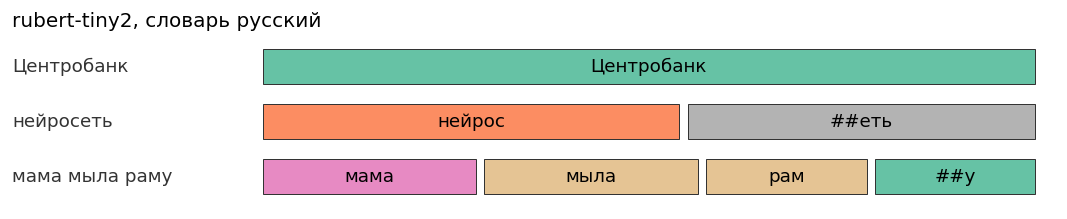


[CLS] 2  [SEP] 3  [PAD] 0  [MASK] 4  [UNK] 1


In [129]:
rows = []
for text in ["Центробанк", "нейросеть", "мама мыла раму"]:
    pieces = tokenizer.tokenize(text)
    print(f"{text:20} {pieces}")
    rows.append((text, pieces))

show_tokens(rows, title="rubert-tiny2, словарь русский")
print()
print(
    "[CLS]", tokenizer.cls_token_id,
    " [SEP]", tokenizer.sep_token_id,
    " [PAD]", tokenizer.pad_token_id,
    " [MASK]", tokenizer.mask_token_id,
    " [UNK]", tokenizer.unk_token_id,
)


Служебные токены сидят в том же словаре.

`[CLS]` ставится первым. Когда нужно одно число на всё предложение, берут вектор этой позиции.

`[SEP]` ставится между двумя текстами и в конце. Вопрос и абзац склеивают в одну последовательность.

`[PAD]` добивает короткие строки батча. Маска внимания на нём нулевая.

`[MASK]` стоит на месте спрятанного слова.

`[UNK]` — куска нет в словаре.

К эмбеддингу токена прибавляют эмбеддинг позиции и эмбеддинг сегмента. Сегмент 0 — первый текст, сегмент 1 — второй.

```
вход = эмбеддинг токена + эмбеддинг позиции + эмбеддинг сегмента
```


[CLS]     сегмент 0  маска 1
кот       сегмент 0  маска 1
сидел     сегмент 0  маска 1
[SEP]     сегмент 0  маска 1
на        сегмент 1  маска 1
ковр      сегмент 1  маска 1
##е       сегмент 1  маска 1
[SEP]     сегмент 1  маска 1


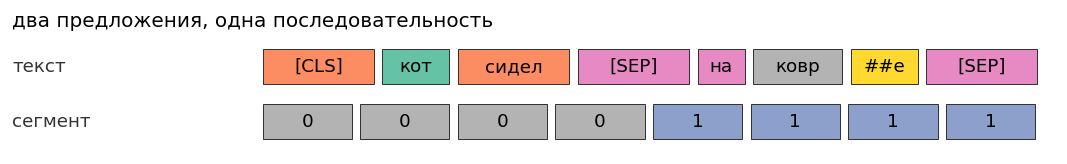

In [130]:
encoded = tokenizer("кот сидел", "на ковре")
tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"])
for tok, seg, keep in zip(tokens, encoded["token_type_ids"], encoded["attention_mask"]):
    print(f"{tok:8}  сегмент {seg}  маска {keep}")

show_tokens([
    ("текст", tokens),
    ("сегмент", [str(s) for s in encoded["token_type_ids"]]),
], title="два предложения, одна последовательность")


In [131]:
batch = tokenizer(["кот сидел", "привет"], padding=True, return_tensors="pt")
for ids, mask in zip(batch["input_ids"], batch["attention_mask"]):
    toks = tokenizer.convert_ids_to_tokens(ids)
    print(list(zip(toks, mask.tolist())))


[('[CLS]', 1), ('кот', 1), ('сидел', 1), ('[SEP]', 1)]
[('[CLS]', 1), ('привет', 1), ('[SEP]', 1), ('[PAD]', 0)]


У второй строки в конце `[PAD]`, маска на этих позициях 0. В внимание они не попадут. Номера токенов при этом в тензоре лежат: паддинг нужен, чтобы строки батча были одной длины.


## 4. Три эмбеддинга


In [132]:
text = "кот сидел"
batch = tokenizer(text, return_tensors="pt")
ids = batch["input_ids"]
pos_ids = torch.arange(ids.size(1)).unsqueeze(0)

word = model.embeddings.word_embeddings(ids)
pos = model.embeddings.position_embeddings(pos_ids)
seg = model.embeddings.token_type_embeddings(batch["token_type_ids"])
raw = word + pos + seg

with torch.no_grad():
    full = model.embeddings(input_ids=ids, token_type_ids=batch["token_type_ids"])

tokens = tokenizer.convert_ids_to_tokens(ids[0])
i = tokens.index("кот")
k = 4

def show(name, vec):
    nums = " ".join(f"{x:8.4f}" for x in vec[0, i, :k].tolist())
    print(f"{name:10} {nums}")

print(f"{tokens[i]}, первые {k} координаты из {word.size(-1)}")
show("слово", word)
print("+")
show("позиция", pos)
print("+")
show("сегмент", seg)
print("=")
show("сумма", raw)
print()
show("LayerNorm", full)


кот, первые 4 координаты из 312
слово       -0.0010   0.0106  -0.0308  -0.0151
+
позиция     -0.0004  -0.0064   0.0204   0.0248
+
сегмент     -0.0092   0.0160  -0.0066  -0.0335
=
сумма       -0.0106   0.0201  -0.0169  -0.0238

LayerNorm    0.1185   0.7664  -0.0640  -0.2425


Первые 4 координаты токена «кот». Вектор целиком длины 312, здесь только начало.

По столбцам это сложение: слово + позиция + сегмент = сумма. Дальше сумма идёт в LayerNorm, координаты после него уже другие. Dropout при `eval()` выключен, сдвиг даёт нормализация.

В статье вход нарисован так. Сегмент A — первое предложение, сегмент B — второе. `##ing` — продолжение слова, тот же WordPiece.

![Вход BERT: токен, сегмент и позиция](figures/bert/input_embeddings.png)


## 5. Прогон


In [133]:
with torch.no_grad():
    out = model(**batch)

print("last_hidden_state", tuple(out.last_hidden_state.shape))
print("pooler_output    ", tuple(out.pooler_output.shape))
print("слоёв внимания   ", len(out.attentions), tuple(out.attentions[0].shape))


last_hidden_state (1, 4, 312)
pooler_output     (1, 312)
слоёв внимания    3 (1, 12, 4, 4)


`last_hidden_state` — вектор на каждый токен, размер `[батч, длина, 312]`. Энкодер двусторонний: позиция видела и левый контекст, и правый.

`pooler_output` — вектор `[CLS]` после линейного слоя и tanh, размер `[батч, 312]`. На классификации часто берут сам `[CLS]` из `last_hidden_state`, без этого слоя.

`attentions` — карта на каждый слой. Форма одной карты: `[батч, головы, длина, длина]`.


## 6. Строка словаря и вектор на выходе

У слова в таблице одна строка. Оба вхождения `мама` берут её.

`слово+позиция` — эта строка плюс позиция и сегмент, затем LayerNorm. Внимания ещё нет, это вход энкодера.

`контекстный` — выход энкодера. Соседи уже смешались через внимание.


In [134]:
model.embeddings

BertEmbeddings(
  (word_embeddings): Embedding(83828, 312, padding_idx=0)
  (position_embeddings): Embedding(2048, 312)
  (token_type_embeddings): Embedding(2, 312)
  (LayerNorm): LayerNorm((312,), eps=1e-12, elementwise_affine=True)
  (dropout): Dropout(p=0.1, inplace=False)
)

In [135]:
text = "мама мыла раму и мама устала"
batch = tokenizer(text, return_tensors="pt")
ids = batch["input_ids"]
word = model.embeddings.word_embeddings(ids)[0]
with torch.no_grad():
    entered = model.embeddings(input_ids=ids, token_type_ids=batch["token_type_ids"])[0]
    ctx = model(**batch).last_hidden_state[0]

tokens = tokenizer.convert_ids_to_tokens(ids[0])
a, b = [i for i, tok in enumerate(tokens) if tok == "мама"]

print(a, b)

def cos(x, y):
    return round(F.cosine_similarity(x, y, dim=0).item(), 3)

def show(pair, x, y):
    print(f"  косинус({pair}): {cos(x, y)}")

print(tokens)
print("две мама")
show("слово, слово", word[a], word[b])

1 6
['[CLS]', 'мама', 'мыла', 'рам', '##у', 'и', 'мама', 'устала', '[SEP]']
две мама
  косинус(слово, слово): 1.0


In [136]:
show("слово+позиция, слово+позиция", entered[a], entered[b])

  косинус(слово+позиция, слово+позиция): 0.797


In [137]:
show("контекстный, контекстный", ctx[a], ctx[b])

  косинус(контекстный, контекстный): 0.743


In [138]:
show("контекстный, слово+позиция", ctx[a], entered[a])

  косинус(контекстный, слово+позиция): 0.592


In [139]:
show("контекстный, слово+позиция", ctx[b], entered[b])

  косинус(контекстный, слово+позиция): 0.71


`косинус(слово, слово)` равен 1: одна строка таблицы. `косинус(слово+позиция, слово+позиция)` уже около 0.80, позиции разные. `косинус(контекстный, контекстный)` около 0.74.

`косинус(контекстный, слово+позиция)` около 0.59 и 0.71. Вектор позиции сдвинулся относительно входа. Трёх слоёв мало, чтобы сильно развести одно слово.


## 7. Одно число на предложение

Берём вектор `[CLS]` и считаем косинус. Близкие фразы должны лежать ближе далёких.


In [140]:
sents = [
    "кот сидел на ковре",
    "кошка лежала на ковре",
    "центробанк снизил ставку",
    "центробанк поднял ставку",
    # "ключевая ставка упала",
]
sent_labels = ["кот", "кошка", "ставка 1", "ставка 2"]


# sents = [
#     "центробанк снизил ставку",
#     "центробанк поднял ставку",
# ]
# sent_labels = ["снижение", "повышение"]

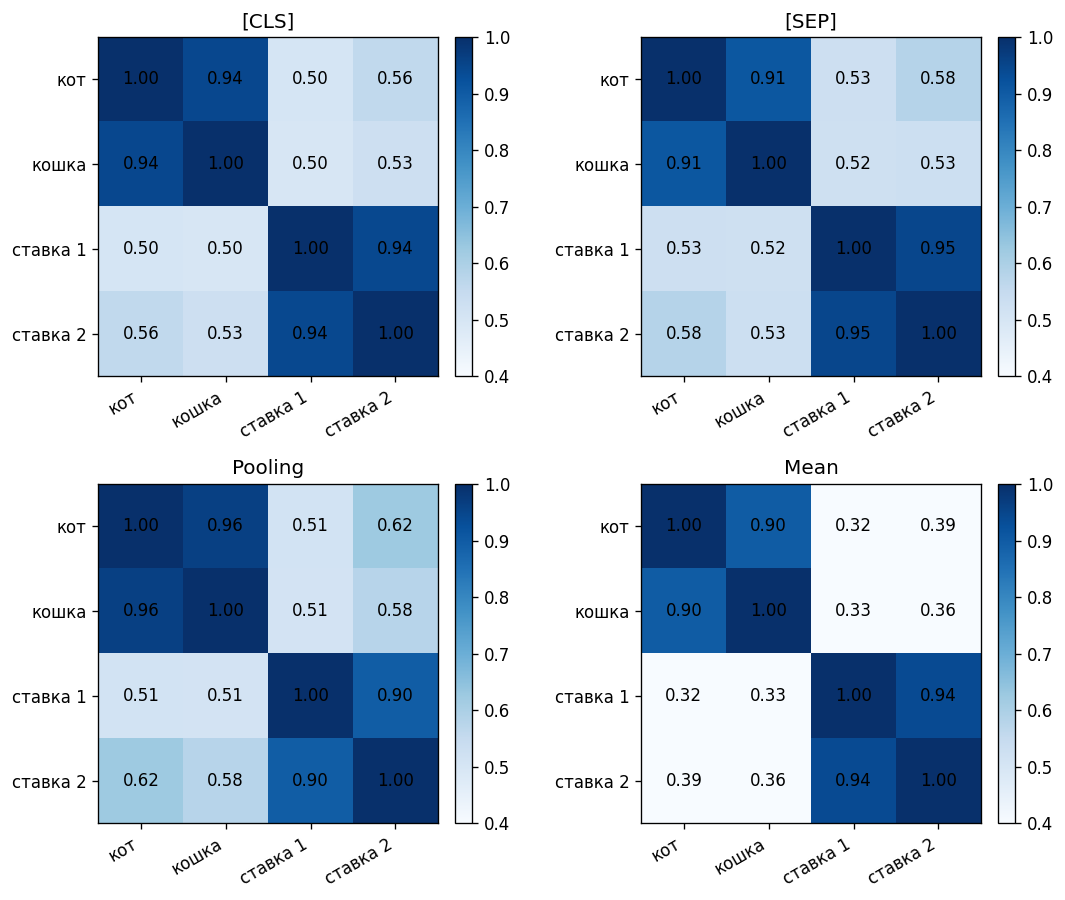

In [141]:
vecs = {"[CLS]": [], "[SEP]": [], "Pooling": [], "Mean": []}
for text in sents:
    batch = tokenizer(text, return_tensors="pt")
    with torch.no_grad():
        out = model(**batch)
        h = out.last_hidden_state[0]
        sep_idx = (batch["input_ids"] == tokenizer.sep_token_id).nonzero(as_tuple=True)[1][0]
        vecs["[CLS]"].append(h[0])
        vecs["[SEP]"].append(h[sep_idx])
        vecs["Pooling"].append(out.pooler_output[0])
        vecs["Mean"].append(h.mean(0))

fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))
for ax, title in zip(axes.flat, vecs):
    rows = vecs[title]
    n = len(rows)
    sim = torch.zeros(n, n)
    for i in range(n):
        for j in range(n):
            sim[i, j] = F.cosine_similarity(rows[i], rows[j], dim=0)
    im = ax.imshow(sim, cmap="Blues", vmin=0.4, vmax=1.0)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(sent_labels, rotation=30, ha="right")
    ax.set_yticklabels(sent_labels)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center")
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


Две фразы про кошку ближе друг к другу, чем к фразам про ставку. Две фразы про ставку тоже ближе между собой. Модель маленькая, порядок виден.


## 8. Внимание

Та же карта, что на семинаре 2.

Строка — запрос: токен, который смотрит. Столбец — ключ: токен, на который смотрят. Число в клетке — доля этого взгляда. Сумма строки равна 1.

Яркая клетка — почти вся строка ушла в этот столбец. Диагональ — токен смотрит на себя.

Ниже слой 0, все двенадцать голов. Они считаются параллельно и не обязаны выбирать один и тот же столбец. Слоёв в модели три, форма карты на каждом такая же.


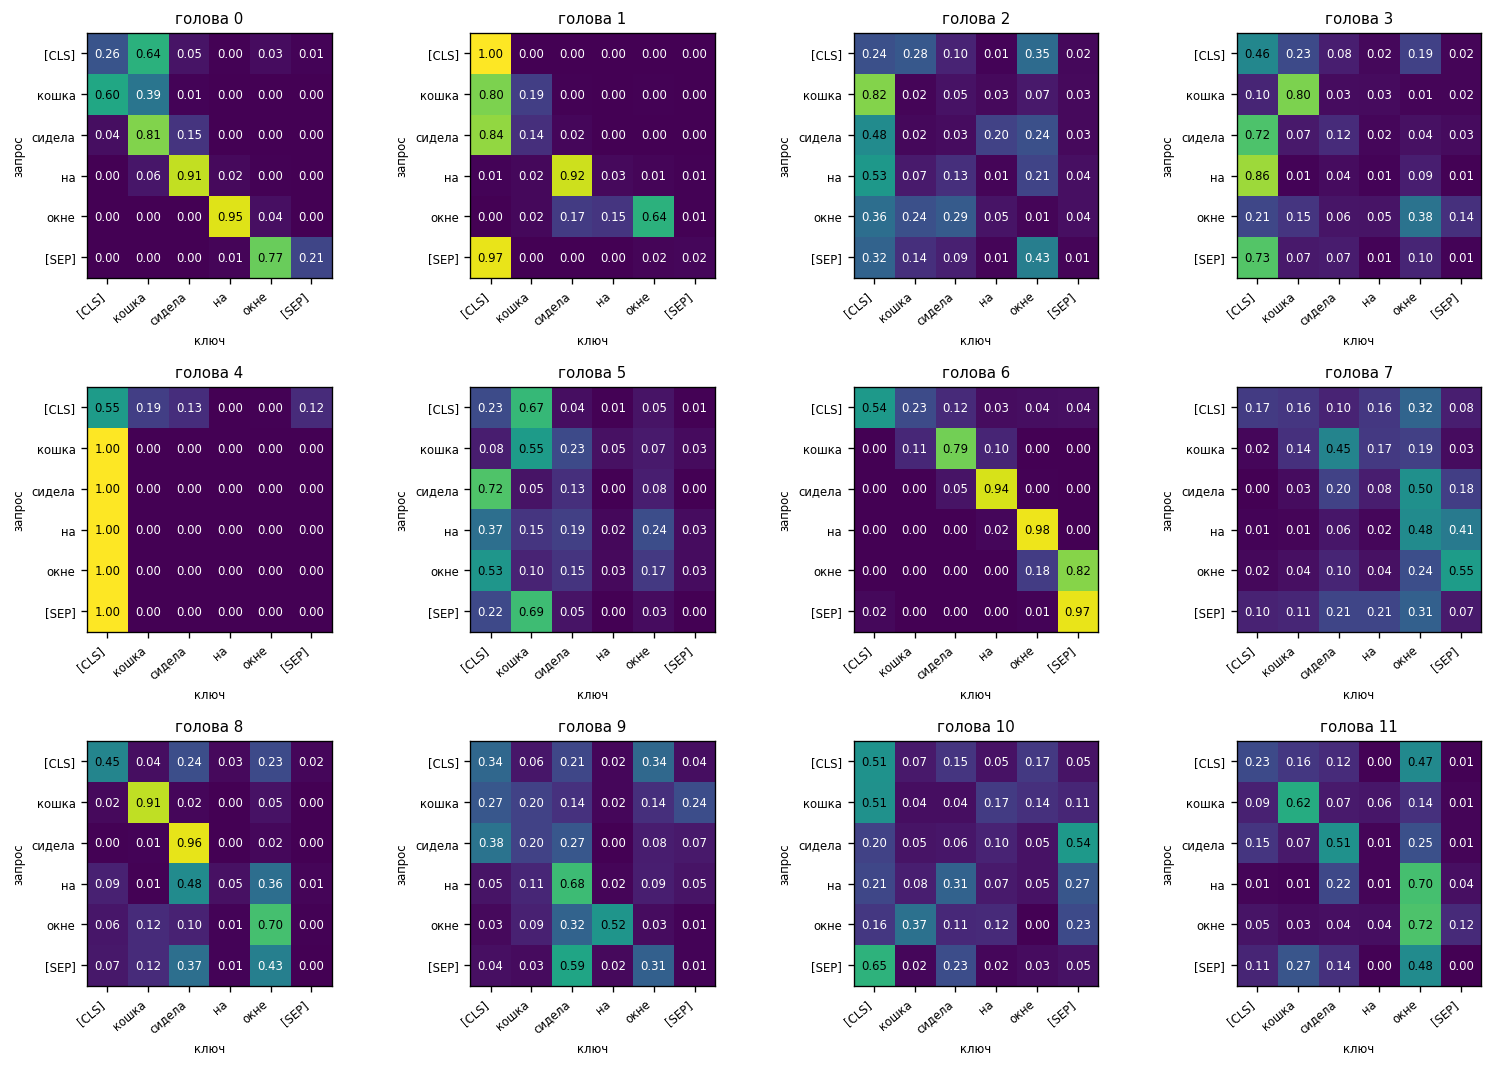

сумма строки: 1.0
окне, слой 0, самый большой вес:
  голова  0  на       0.95
  голова  1  окне     0.64
  голова  2  [CLS]    0.36
  голова  3  окне     0.38
  голова  4  [CLS]    1.00
  голова  5  [CLS]    0.53
  голова  6  [SEP]    0.82
  голова  7  [SEP]    0.55
  голова  8  окне     0.70
  голова  9  на       0.52
  голова 10  кошка    0.37
  голова 11  окне     0.72


In [142]:
text = "кошка сидела на окне"
batch = tokenizer(text, return_tensors="pt")
with torch.no_grad():
    out = model(**batch)

labels = tokenizer.convert_ids_to_tokens(batch["input_ids"][0])
attn = out.attentions[0][0]
fig, axes = plt.subplots(3, 4, figsize=(13, 9))
for head, ax in enumerate(axes.flat):
    plot_attention(attn[head], labels, labels, title=f"голова {head}", ax=ax, fontsize=7, colorbar=False)
plt.tight_layout()
plt.show()

i = labels.index("окне")
print("сумма строки:", round(attn[0, i].sum().item(), 3))
print("окне, слой 0, самый большой вес:")
for head in range(attn.size(0)):
    row = attn[head, i]
    j = int(row.argmax())
    print(f"  голова {head:2}  {labels[j]:8} {row[j]:.2f}")


На «окне» голова 0 почти целиком смотрит на «на»: в строке «окне» столбец «на» около 0.95. Другие головы той же строки уходят в другие столбцы. Соседний предлог — не толкование слова.

На `[PAD]` маска нулевая, эти ключи в softmax не входят. В этом примере паддинга нет.


## 9. Спрятанное слово

Энкодер видит предложение целиком. Следующее слово предсказывать незачем: оно уже стоит справа. На обучении часть токенов закрывают и просят восстановить их по остальным. Это masked language model.

Выбирают около 15% позиций. На месте токена:

- в 80% случаев пишут `[MASK]`;
- в 10% подставляют случайный токен;
- в 10% оставляют исходный.

Спрашивают одно и то же: какое слово здесь было. Для «окне» во фразе «кошка сидела на окне» вход выглядит так.

- `[MASK]`: «кошка сидела на [MASK]». Дырка видна, слово берут у соседей.
- Исходный токен: «кошка сидела на окне». Слово на месте, но назвать его всё равно просят. Потом `[MASK]` в тексте не будет, надо уметь работать с обычными словами.
- Случайный токен: «кошка сидела на банан». Если списать то, что написано в слоте, ответ будет «банан». Приходится смотреть на «кошка сидела на». Таких позиций мало: 10% от 15%, около 1.5% текста.

Голову не учим. Она уже в весах. `BertForMaskedLM` — тот же энкодер плюс слой на размер словаря. На позиции `[MASK]` считают softmax по 83828 токенам.

![Две дырки в одном предложении](figures/bert/mlm_example.png)

Две позиции спрятаны в одном предложении. Модель восстанавливает их по остальному тексту, слева и справа.


In [143]:
mlm = BertForMaskedLM.from_pretrained(name, local_files_only=True)
mlm.eval()

words = "кошка сидела на окне".split()
i = words.index("окне")

def variant(token):
    row = words.copy()
    row[i] = token
    return " ".join(row)

print("дырка:     ", variant("[MASK]"))
print("исходный:  ", variant("окне"))
print("случайный: ", variant("банан"))
print()

дырка:      кошка сидела на [MASK]
исходный:   кошка сидела на окне
случайный:  кошка сидела на банан



In [151]:
def fill(text, k=5):
    batch = tokenizer(text, return_tensors="pt")
    with torch.no_grad():
        logits = mlm(**batch).logits[0]
    i = (batch["input_ids"][0] == tokenizer.mask_token_id).nonzero()[0].item()
    top = logits[i].softmax(dim=-1).topk(k)
    print(text)
    for idx, prob in zip(top.indices.tolist(), top.values.tolist()):
        print(f"  {tokenizer.convert_ids_to_tokens(idx):12} {prob:.3f}")
    print()


fill("Москва это столица [MASK].")
fill("кошка сидела на [MASK] у окна")

Москва это столица [MASK].
  России       0.170
  страны       0.066
  Москвы       0.059
  столицы      0.055
  Украины      0.051

кошка сидела на [MASK] у окна
  диване       0.093
  улице        0.057
  месте        0.041
  балконе      0.041
  столе        0.029



`России` на первом месте с вероятностью около 0.17. На второй дырке первое слово — `диване`. Модель маленькая, список всё равно про страну и место, не про случайный токен.

Вектор позиции `[MASK]` прогоняют через небольшой слой и умножают на таблицу словаря. Та же матрица, что у эмбеддинга токена, только как выход, не как вход.


## 10. Как учили оригинальный BERT

Статья Devlin et al., NAACL 2019. Архитектура — энкодер трансформера, декодера нет. Каждый токен видит всю последовательность.

Два размера. BERT-base: 12 слоёв, вектор 768, 12 голов, около 110 миллионов параметров. BERT-large: 24 слоя, вектор 1024, 16 голов, около 340 миллионов. На семинаре крутим `rubert-tiny2`: 3 слоя, вектор 312, 12 голов. Схема та же, модель меньше base.

Корпус — английская Wikipedia и BookCorpus, около 16 ГБ текста. Словарь WordPiece, 30 000 токенов. Длина входа до 512.

Учили сразу на двух задачах.

MLM мы уже вызвали. Прячут 15% позиций. Потеря — кросс-энтропия только по ним, не по каждому токену предложения.

NSP смотрит на пару предложений через `[SEP]`. В половине случаев второе правда шло следом, в половине его взяли случайно. Ответ читают с `[CLS]`: next или not next. Эту потерю складывают с MLM.

$$\mathcal{L} = \mathcal{L}_{\text{MLM}} + \mathcal{L}_{\text{NSP}}$$

![MLM и NSP на одном проходе](figures/bert/mlm_nsp.png)

`[CLS]` идёт в голову «следующее предложение или нет». На `[MASK]` — softmax по словарю. После `[SEP]` второй сегмент, у него другие эмбеддинги сегмента.

Веса после этого не выбрасывают. На размеченной задаче архитектуру не меняют: для классификации берут `[CLS]`, для ответа в тексте — векторы токенов. Дообучение короче предобучения.

![Предобучение и дообучение](figures/bert/pretrain_finetune.png)

Слева сырые пары предложений. Справа те же веса и другая голова: класс пары, метка на токене или границы ответа.

Перед этим иногда прогоняют тот же MLM на текстах своей области. На схеме это средний шаг, его можно пропустить.

![Три шага: общий корпус, своя область, задача](figures/bert/bert_pipeline.png)


## 11. Что поменяли после

Энкодер оставили. Меняли данные, маску и задачу.

### RoBERTa

RoBERTa (2019) — тот же BERT, другое обучение.

Данных больше: 16 ГБ стали около 160 ГБ. Батч вырос с 256 до 2–8 тысяч последовательностей.

Маску в BERT заготавливали заранее: последовательность копировали и каждый раз закрывали другие позиции. В RoBERTa маска новая на каждом батче.

![Статическая и динамическая маска](figures/bert/roberta_masking.png)

Прирост маленький. Основной выигрыш не в этой таблице.

NSP убрали. Вместо пары коротких кусков склеивают предложения из одного документа, пока не наберётся 512 токенов.

![NSP и нарезка входа](figures/bert/roberta_nsp.png)

DOC-SENTENCES без NSP выше, чем SEGMENT-PAIR с NSP, как у BERT. Задачу «идёт ли второе предложение следом» выкинули.

Словарь тоже другой: не WordPiece на 30 тысяч, а byte-level BPE на 50 тысяч. Старт с 256 байтов, отдельный `[UNK]` почти не нужен.

### XLM-RoBERTa

Та же RoBERTa на 100 языках и 2.5 ТБ Common Crawl. Словарь SentencePiece, 250 тысяч токенов, задача снова только MLM. Около половины параметров — таблица слов.

Если доучить голову на английских примерах, она часто работает на другом языке без размеченных примеров на нём. Параметры при этом делятся между языками: на английском одноязычная RoBERTa того же размера сильнее.

### DeBERTa

Здесь меняется внимание.

В BERT слово и позиция складываются в один вектор до внимания. DeBERTa считает три слагаемых отдельно: содержание к содержанию, содержание к относительной позиции, позиция к содержанию. Абсолютный номер позиции на вход не подают. Его добавляют запросом на последнем слое, перед головой MLM.

![Голова предсказания токена](figures/bert/deberta_decoder.png)

Слева у BERT позиция уже сидит внутри H. Справа абсолютные позиции I приходят только перед восстановлением токена.

### ELECTRA и DeBERTaV3

В MLM градиент есть на 15% позиций. ELECTRA подменяет часть токенов маленькой моделью и на каждом токене спрашивает: оригинал это или подмена. Учится вся последовательность, не только дырки. DeBERTaV3 ставит это вместо MLM.

![GLUE, модели размера large](figures/bert/deberta_v3.png)

На этой таблице порядок такой: BERT, RoBERTa, DeBERTa, DeBERTaV3. Сеть энкодера общая. Разница — в данных, в задаче предобучения и в том, как в внимание попадает позиция.

### Русский

Английский BERT русское слово режет на буквы: в словаре нет русских кусков. Для русского учат отдельную модель на русском корпусе и со своим словарём. RuBERT-base от Sber — тот же BERT, BPE, словарь около 120 тысяч токенов. Рядом на том же корпусе лежат RoBERTa и ELECTRA.


## 12. Задания

В каждой ячейке поменяй строки вверху и запусти ещё раз.


### 1. Где слово разрезали

Три фразы. Печатаем не все токены, а только те слова, которые стали несколькими кусками.


In [145]:
phrases = [
    "Центробанк снизил ставку",
    "нейросеть мыла раму",
    "мама устала",
]

for phrase in phrases:
    groups = []
    for tok in tokenizer.tokenize(phrase):
        if tok.startswith("##") and groups:
            groups[-1].append(tok)
        else:
            groups.append([tok])
    cut = [" ".join(g) for g in groups if len(g) > 1]
    print(phrase)
    print(" ", ", ".join(cut) if cut else "целиком")


Центробанк снизил ставку
  целиком
нейросеть мыла раму
  нейрос ##еть, рам ##у
мама устала
  целиком


### 2. Одно слово на двух местах

Та же тройка косинусов, что у «мама». Слово в `word_tok` должно встретиться дважды и быть одним токеном.


In [146]:
text = "кот сидел на окне и кот ушёл"
word_tok = "кот"
batch = tokenizer(text, return_tensors="pt")
ids = batch["input_ids"]
word = model.embeddings.word_embeddings(ids)[0]
with torch.no_grad():
    entered = model.embeddings(input_ids=ids, token_type_ids=batch["token_type_ids"])[0]
    ctx = model(**batch).last_hidden_state[0]

tokens = tokenizer.convert_ids_to_tokens(ids[0])
a, b = [i for i, tok in enumerate(tokens) if tok == word_tok]

def cos(x, y):
    return round(F.cosine_similarity(x, y, dim=0).item(), 3)

print(tokens)
print("косинус(слово, слово):                ", cos(word[a], word[b]))
print("косинус(слово+позиция, слово+позиция):", cos(entered[a], entered[b]))
print("косинус(контекстный, контекстный):    ", cos(ctx[a], ctx[b]))


['[CLS]', 'кот', 'сидел', 'на', 'окне', 'и', 'кот', 'ушёл', '[SEP]']
косинус(слово, слово):                 1.0
косинус(слово+позиция, слово+позиция): 0.813
косинус(контекстный, контекстный):     0.658


### 3. Куда смотрит токен

Слой 0, все головы. Для `token` печатается столбец с самым большим весом. Скажи, кто смотрит на соседа, кто на себя, кто на `[CLS]`.


In [147]:
text = "кошка сидела на окне"
token = "окне"
batch = tokenizer(text, return_tensors="pt")
with torch.no_grad():
    attn = model(**batch).attentions[0][0]

labels = tokenizer.convert_ids_to_tokens(batch["input_ids"][0])
i = labels.index(token)
print(token)
for head in range(attn.size(0)):
    j = int(attn[head, i].argmax())
    print(f"  голова {head:2}  {labels[j]}")


окне
  голова  0  на
  голова  1  окне
  голова  2  [CLS]
  голова  3  окне
  голова  4  [CLS]
  голова  5  [CLS]
  голова  6  [SEP]
  голова  7  [SEP]
  голова  8  окне
  голова  9  на
  голова 10  кошка
  голова 11  окне


### 4. Три входа в одну дырку

`hide` — один токен в середине фразы. Ячейка ставит на его место `[MASK]`, само слово и случайный токен. Сравни топ-1: совпал ли он с тем, что стоит в слоте.


In [148]:
text = "кошка сидела на окне у двери"
hide = "окне"
other = "банан"

def put(token):
    return text.replace(hide, token, 1)

def top1(sentence, slot):
    batch = tokenizer(sentence, return_tensors="pt")
    ids = batch["input_ids"][0]
    labels = tokenizer.convert_ids_to_tokens(ids)
    i = labels.index(slot)
    with torch.no_grad():
        prob = mlm(**batch).logits[0, i].softmax(dim=-1)
    j = int(prob.argmax())
    return tokenizer.convert_ids_to_tokens(j), round(prob[j].item(), 3)

for name, sentence, slot in [
    ("дырка", put("[MASK]"), "[MASK]"),
    ("исходный", put(hide), hide),
    ("случайный", put(other), other),
]:
    guess, p = top1(sentence, slot)
    print(f"{name:10} {sentence}")
    print(f"{'':10} топ-1 {guess}  {p}")


дырка      кошка сидела на [MASK] у двери
           топ-1 улице  0.07
исходный   кошка сидела на окне у двери
           топ-1 окне  0.67
случайный  кошка сидела на банан у двери
           топ-1 банан  0.649


### 5. Два сегмента

Две фразы в одном вызове. Рядом с токеном его `token_type_ids`. Косинус эмбеддингов сегмента: внутри первой фразы и через `[SEP]`.


In [149]:
first, second = "кот сидел", "собака спала"
batch = tokenizer(first, second, return_tensors="pt")
tokens = tokenizer.convert_ids_to_tokens(batch["input_ids"][0])
segs = batch["token_type_ids"][0]
emb = model.embeddings.token_type_embeddings(segs)

for tok, seg in zip(tokens, segs.tolist()):
    print(f"{tok:10} {seg}")

def cos(x, y):
    return round(F.cosine_similarity(emb[x], emb[y], dim=0).item(), 3)

i, j = tokens.index("кот"), tokens.index("сидел")
k = tokens.index("собака")
print("кот и сидел:  ", cos(i, j))
print("кот и собака: ", cos(i, k))


[CLS]      0
кот        0
сидел      0
[SEP]      0
собака     1
спала      1
[SEP]      1
кот и сидел:   1.0
кот и собака:  0.079


## 13. Контрольные вопросы

1. Чем папка на Hub отличается от вызова `from_pretrained`?
2. Почему `AutoModel` на `models/rubert-tiny2` собирает BERT?
3. Зачем `attention_mask`, если `[PAD]` и так есть в словаре?
4. Зачем `token_type_ids`, если тексты уже разделены `[SEP]`?
5. Две `мама` в таблице имеют косинус 1. Почему `косинус(контекстный, слово+позиция)` меньше 1?
6. Почему BERT учит спрятанный токен, а не следующее слово?
7. Почему «Центробанк» один токен, а «раму» режется на `рам` и `##у`?
8. Зачем в оригинальном BERT была задача NSP и почему в RoBERTa её убрали?
9. Чем динамическая маска отличается от статической?
10. Что DeBERTa не складывает в один вектор до внимания?


## 14. Короткий конспект

- Hugging Face Hub хранит папку модели. Библиотека `transformers` читает её через `from_pretrained`. Класс выбирают по `model_type`.
- В папке три файла: `config.json`, `vocab.txt`, веса. Номер токена — строка матрицы эмбеддингов.
- На вход идут номера токенов, маска внимания и номер сегмента. `[CLS]` первый, `[SEP]` между текстами и в конце, `[PAD]` выравнивает батч.
- Вход слоя — сумма эмбеддинга токена, позиции и сегмента, дальше LayerNorm.
- `last_hidden_state` — вектор на каждый токен после всех слоёв. Он уже не равен строке словаря.
- Вектор `[CLS]` используют как одно число на предложение. Близкие фразы дают больший косинус.
- Оригинальный BERT учили на Wikipedia и BookCorpus сразу на двух задачах: MLM по 15% позиций и NSP по паре предложений. Потом те же веса доучивают на размеченной задаче.
- RoBERTa оставила сеть и убрала NSP, увеличила данные и батч, маску ставит заново на каждом батче, словарь — byte-level BPE.
- XLM-RoBERTa — та же схема на 100 языках. DeBERTa разделяет внимание к слову и к позиции. DeBERTaV3 вместо MLM определяет подменённые токены, как ELECTRA.
- `rubert-tiny2` — тот же BERT на русском словаре: 3 слоя, вектор 312, 12 голов.
